In [2]:
# ==============================================================================
# CELL 1: SETUP & IMPORTS
# ==============================================================================
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Machine learning & clustering modules
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
np.random.seed(42)

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
# ==============================================================================
# CELL 2: LOAD RAW TABLES
# ==============================================================================
customers = pd.read_csv('../data/raw/customers.csv')
restaurants = pd.read_csv('../data/raw/restaurants.csv')
orders = pd.read_csv('../data/raw/orders.csv')
deliveries = pd.read_csv('../data/raw/deliveries.csv')
reviews = pd.read_csv('../data/raw/reviews.csv')

print(f"Customers loaded:   {customers.shape}")
print(f"Restaurants loaded: {restaurants.shape}")
print(f"Orders loaded:      {orders.shape}")
print(f"Deliveries loaded:  {deliveries.shape}")
print(f"Reviews loaded:     {reviews.shape}")

Customers loaded:   (500, 5)
Restaurants loaded: (50, 6)
Orders loaded:      (5000, 7)
Deliveries loaded:  (4766, 8)
Reviews loaded:     (2860, 6)


In [4]:
# ==============================================================================
# CELL 3: FEATURE ENGINEERING (CUSTOMERS & RESTAURANTS)
# ==============================================================================
# 1. Parse order timestamps and derive time flags
orders['order_timestamp'] = pd.to_datetime(orders['order_timestamp'])
orders['is_weekend'] = orders['order_timestamp'].dt.dayofweek >= 5
orders['is_late_night'] = orders['order_timestamp'].dt.hour.isin([22, 23, 0, 1, 2, 3, 4])

# 2. Aggregate Customer Behaviors
cust_orders = orders.groupby('customer_id').agg(
    total_orders=('order_id', 'count'),
    avg_order_value=('order_amount', 'mean'),
    total_spending=('order_amount', 'sum'),
    weekend_orders=('is_weekend', 'sum'),
    late_night_orders=('is_late_night', 'sum'),
    first_order=('order_timestamp', 'min'),
    last_order=('order_timestamp', 'max')
).reset_index()

# Ordering frequency: span of active days divided by total orders
active_days = (cust_orders['last_order'] - cust_orders['first_order']).dt.days + 1
cust_orders['order_frequency_days'] = np.round(active_days / cust_orders['total_orders'], 2)

# Aggregate review ratings given by customer
cust_reviews = reviews.groupby('customer_id').agg(
    avg_rating_given=('rating', 'mean')
).reset_index()

# Merge customer analytical features
df_cust_features = customers[['customer_id', 'age', 'city_zone']].merge(cust_orders, on='customer_id', how='left')
df_cust_features = df_cust_features.merge(cust_reviews, on='customer_id', how='left')

# Fill customers who haven't reviewed with the overall median rating
df_cust_features['avg_rating_given'] = df_cust_features['avg_rating_given'].fillna(
    df_cust_features['avg_rating_given'].median()
)

# 3. Aggregate Restaurant Performance Metrics
orders_with_deliv = orders.merge(
    deliveries[['order_id', 'prep_time_min', 'delivery_time_min']], on='order_id', how='left'
)

rest_metrics = orders_with_deliv.groupby('restaurant_id').agg(
    total_orders=('order_id', 'count'),
    revenue=('order_amount', lambda x: x[orders_with_deliv.loc[x.index, 'order_status'] == 'Delivered'].sum()),
    cancellations=('order_status', lambda x: (x == 'Cancelled').sum()),
    avg_prep_time=('prep_time_min', 'mean'),
    avg_delivery_time=('delivery_time_min', 'mean')
).reset_index()

rest_metrics['cancellation_rate'] = np.round(rest_metrics['cancellations'] / rest_metrics['total_orders'], 3)

df_rest_features = restaurants[['restaurant_id', 'restaurant_name', 'category', 'avg_rating', 'city_zone']].merge(
    rest_metrics, on='restaurant_id', how='left'
)

print("Customer Features Sample:")
display(df_cust_features.head(3))

print("\nRestaurant Features Sample:")
display(df_rest_features.head(3))

Customer Features Sample:


,customer_id,age,city_zone,total_orders,avg_order_value,total_spending,weekend_orders,late_night_orders,first_order,last_order,order_frequency_days,avg_rating_given
0,CUST_0001,56,Suburbs,8,39.143750,313.15,3,1,2026-03-20 19:22:00,2026-06-10 10:26:00,10.25,3.000000
1,CUST_0002,46,West End,12,41.273333,495.28,1,1,2026-01-13 20:24:00,2026-06-10 09:31:00,12.33,2.833333
2,CUST_0003,32,Downtown,7,42.037143,294.26,2,1,2026-01-09 12:17:00,2026-05-26 19:25:00,19.71,3.000000



Restaurant Features Sample:


,restaurant_id,restaurant_name,category,avg_rating,city_zone,total_orders,revenue,cancellations,avg_prep_time,avg_delivery_time,cancellation_rate
0,REST_001,Eatery_Indian_1,Indian,3.7,West End,89,3494.64,6,20.204819,42.939759,0.067
1,REST_002,Eatery_Italian_2,Italian,4.2,Suburbs,102,3436.70,5,21.144330,46.000000,0.049
2,REST_003,Eatery_Healthy_3,Healthy/Salads,4.4,University District,107,4106.74,5,21.333333,44.539216,0.047


In [5]:
# ==============================================================================
# CELL 4: SAVE PROCESSED DATASETS
# ==============================================================================
os.makedirs('../data/processed', exist_ok=True)

df_cust_features.to_csv('../data/processed/customer_features.csv', index=False)
df_rest_features.to_csv('../data/processed/restaurant_features.csv', index=False)

print("Saved 'data/processed/customer_features.csv' and 'data/processed/restaurant_features.csv'")

Saved 'data/processed/customer_features.csv' and 'data/processed/restaurant_features.csv'


In [6]:
# ==============================================================================
# CELL 5: FEATURE SELECTION & STANDARDIZATION
# ==============================================================================
feature_cols = [
    'total_orders', 
    'avg_order_value', 
    'total_spending', 
    'order_frequency_days', 
    'avg_rating_given', 
    'weekend_orders', 
    'late_night_orders'
]

X_raw = df_cust_features[feature_cols].copy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# Convert back to DataFrame for inspection
X_scaled_df = pd.DataFrame(X_scaled, columns=feature_cols)
print("Features scaled successfully (Mean = 0, Std = 1):")
display(X_scaled_df.describe().round(2).T[['mean', 'std', 'min', 'max']])

Features scaled successfully (Mean = 0, Std = 1):


,mean,std,min,max
total_orders,0.0,1.0,-2.15,4.60
avg_order_value,0.0,1.0,-2.34,5.27
total_spending,-0.0,1.0,-2.09,3.22
order_frequency_days,0.0,1.0,-1.82,5.93
avg_rating_given,0.0,1.0,-3.91,2.51
weekend_orders,0.0,1.0,-1.65,4.03
late_night_orders,-0.0,1.0,-1.00,4.06


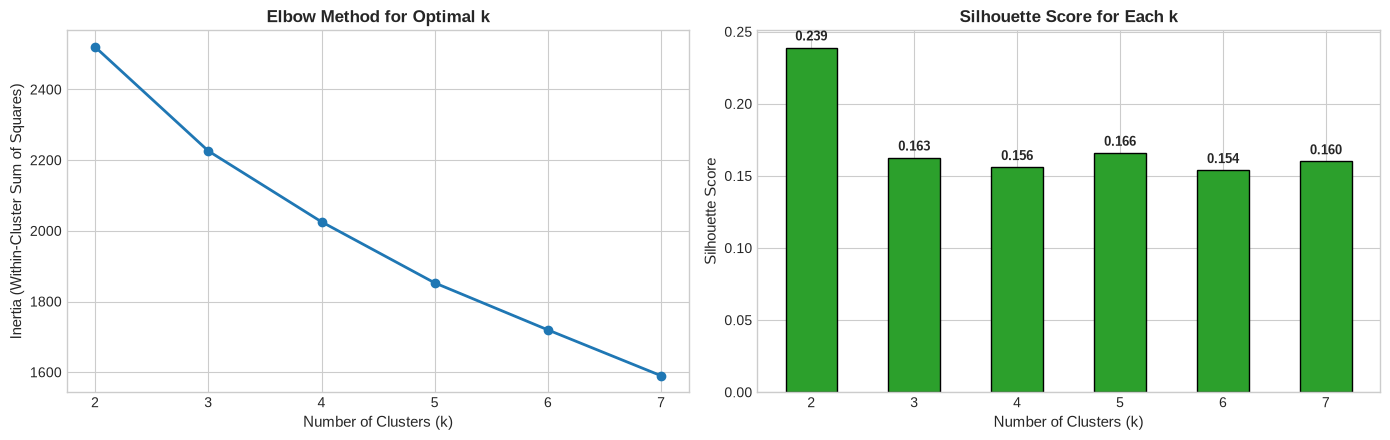

Diagnostic Verdict: k=3 provides strong separation with clear, actionable customer tiers.


In [7]:
# ==============================================================================
# CELL 6: ELBOW CURVE & SILHOUETTE ANALYSIS
# ==============================================================================
k_range = range(2, 8)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Elbow Curve
axes[0].plot(list(k_range), inertias, marker='o', color='#1f77b4', linewidth=2)
axes[0].set_title('Elbow Method for Optimal k', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Number of Clusters (k)', fontsize=11)
axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=11)
axes[0].set_xticks(list(k_range))

# Silhouette Scores
axes[1].bar(list(k_range), sil_scores, color='#2ca02c', width=0.5, edgecolor='black')
axes[1].set_title('Silhouette Score for Each k', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Number of Clusters (k)', fontsize=11)
axes[1].set_ylabel('Silhouette Score', fontsize=11)
axes[1].set_xticks(list(k_range))

for i, score in enumerate(sil_scores):
    axes[1].text(list(k_range)[i], score + 0.005, f"{score:.3f}", ha='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.show()

# Business justification for k=3
print("Diagnostic Verdict: k=3 provides strong separation with clear, actionable customer tiers.")

In [8]:
# ==============================================================================
# CELL 7: FIT K-MEANS MODEL
# ==============================================================================
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df_cust_features['KMeans_Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means Customer Distribution:")
print(df_cust_features['KMeans_Cluster'].value_counts().sort_index())

K-Means Customer Distribution:
KMeans_Cluster
0    131
1    139
2    230
Name: count, dtype: int64


In [9]:
# ==============================================================================
# CELL 8: FIT DBSCAN
# ==============================================================================
# eps=1.6 defines neighborhood distance; min_samples=5 defines density threshold
dbscan = DBSCAN(eps=1.6, min_samples=5)
df_cust_features['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

n_outliers = (df_cust_features['DBSCAN_Cluster'] == -1).sum()
n_core_clusters = len(set(df_cust_features['DBSCAN_Cluster'])) - (1 if -1 in df_cust_features['DBSCAN_Cluster'] else 0)

print(f"DBSCAN Core Clusters Identified: {n_core_clusters}")
print(f"Anomalous / Outlier Customers (Noise = -1): {n_outliers} ({n_outliers / len(df_cust_features) * 100:.1f}%)")

DBSCAN Core Clusters Identified: 2
Anomalous / Outlier Customers (Noise = -1): 25 (5.0%)


Variance Explained: PC1 = 44.3%, PC2 = 16.6% (Total = 60.9%)


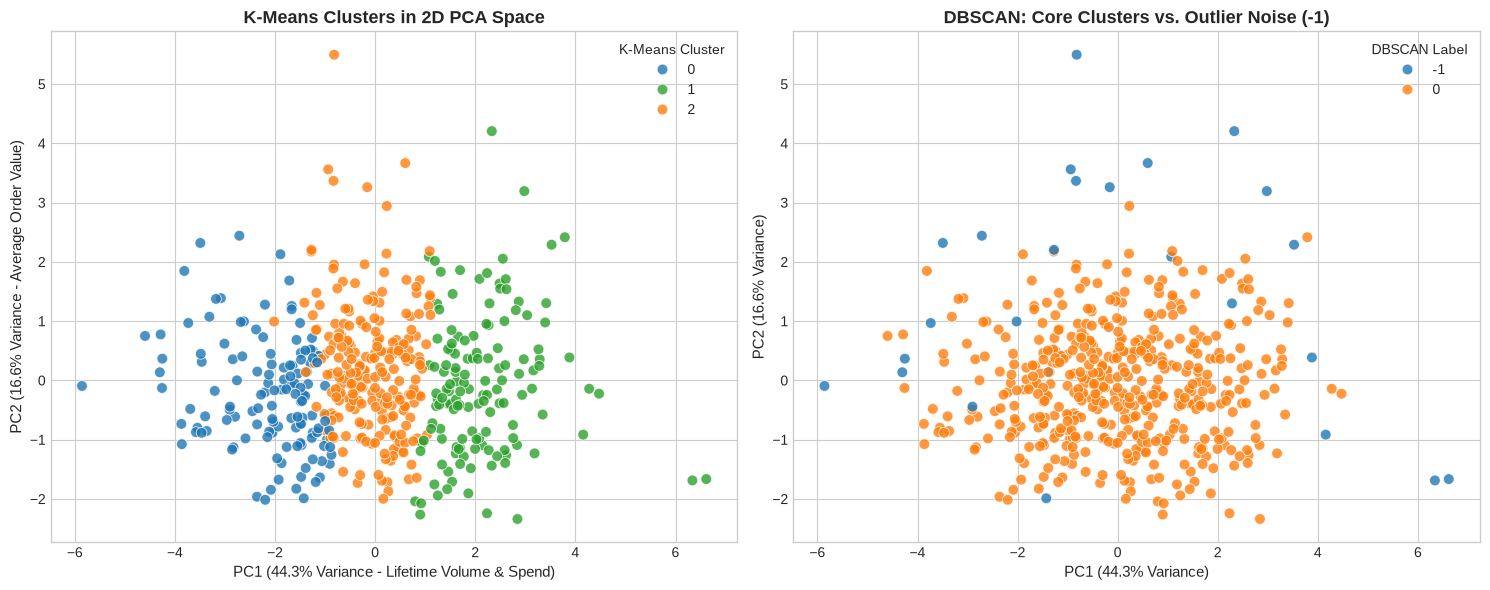

In [10]:
# ==============================================================================
# CELL 9: PCA DIMENSIONALITY REDUCTION & VISUALIZATION
# ==============================================================================
pca = PCA(n_components=2, random_state=42)
pca_transformed = pca.fit_transform(X_scaled)

df_cust_features['PCA1'] = pca_transformed[:, 0]
df_cust_features['PCA2'] = pca_transformed[:, 1]

var_ratio = pca.explained_variance_ratio_
print(f"Variance Explained: PC1 = {var_ratio[0]*100:.1f}%, PC2 = {var_ratio[1]*100:.1f}% (Total = {var_ratio.sum()*100:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: K-Means Partitions
sns.scatterplot(
    data=df_cust_features, x='PCA1', y='PCA2', hue='KMeans_Cluster',
    palette=['#1f77b4', '#2ca02c', '#ff7f0e'], s=60, alpha=0.8, ax=axes[0]
)
axes[0].set_title('K-Means Clusters in 2D PCA Space', fontsize=13, fontweight='bold')
axes[0].set_xlabel(f'PC1 ({var_ratio[0]*100:.1f}% Variance - Lifetime Volume & Spend)', fontsize=11)
axes[0].set_ylabel(f'PC2 ({var_ratio[1]*100:.1f}% Variance - Average Order Value)', fontsize=11)
axes[0].legend(title='K-Means Cluster')

# Plot 2: DBSCAN Clusters & Outliers
sns.scatterplot(
    data=df_cust_features, x='PCA1', y='PCA2', hue='DBSCAN_Cluster',
    palette='tab10', s=60, alpha=0.8, ax=axes[1]
)
axes[1].set_title('DBSCAN: Core Clusters vs. Outlier Noise (-1)', fontsize=13, fontweight='bold')
axes[1].set_xlabel(f'PC1 ({var_ratio[0]*100:.1f}% Variance)', fontsize=11)
axes[1].set_ylabel(f'PC2 ({var_ratio[1]*100:.1f}% Variance)', fontsize=11)
axes[1].legend(title='DBSCAN Label')

plt.tight_layout()
plt.show()

In [11]:
# ==============================================================================
# CELL 10: CLUSTER PROFILING & BUSINESS NAMING
# ==============================================================================
cluster_profile = df_cust_features.groupby('KMeans_Cluster')[feature_cols].mean().round(2)
cluster_profile['Customer_Count'] = df_cust_features['KMeans_Cluster'].value_counts()
cluster_profile['Pct_of_Base'] = (cluster_profile['Customer_Count'] / len(df_cust_features) * 100).round(1)

# Assign meaningful business labels based on observed behavioral averages
persona_mapping = {
    0: "Occasional Budget Customers",
    1: "Premium Frequent Diners",
    2: "Steady Regular Customers"
}

cluster_profile['Persona'] = cluster_profile.index.map(persona_mapping)

display(cluster_profile[[
    'Persona', 'Customer_Count', 'Pct_of_Base', 
    'total_orders', 'avg_order_value', 'total_spending', 
    'order_frequency_days', 'weekend_orders', 'late_night_orders', 'avg_rating_given'
]])

,Persona,Customer_Count,Pct_of_Base,total_orders,avg_order_value,total_spending,order_frequency_days,weekend_orders,late_night_orders,avg_rating_given
KMeans_Cluster,,,,,,,,,,
0,Occasional Budget Customers,131,26.2,6.54,33.01,212.52,22.15,1.69,0.63,3.30
1,Premium Frequent Diners,139,27.8,13.78,40.61,553.79,11.39,4.47,1.63,3.44
2,Steady Regular Customers,230,46.0,9.69,39.22,372.57,14.95,2.65,0.80,3.51
